# Análise exploratória do `dataset_captcha`

Dataset gerado por `Dataset/Gerar_dataset.py` com a biblioteca `captcha` (`ImageCaptcha`, 160×60, 5 caracteres A–Z/0–9).
O notebook segue a ordem **dados → rótulos → visual → ligação com a interpretabilidade → erros dos modelos**.

Execute com o kernel do `.venv` do projeto, a partir da raiz do repositório ou da pasta `Notebooks/`.
As figuras e tabelas são salvas em `resultados_bernardo/eda/`.

| Seção | Pergunta |
|---|---|
| 1. Integridade | Os arquivos estão íntegros e no formato esperado? Há textos repetidos? |
| 2. Splits | Como fica a divisão 70/15/15 do `Datamodule.py`? Algum texto repetido cruza splits? |
| 3. Rótulos | As 36 classes estão equilibradas, no geral, por posição e por split? |
| 4. Visual | Como são as imagens: cores, contraste, quantidade de "tinta", imagem média? |
| 5. Interpretabilidade | Onde cada um dos 5 caracteres costuma ficar? Eles se sobrepõem? Que glifos se parecem? |
| 6. Erros dos modelos | Quais trocas de caracteres os modelos realmente fazem no ataque local? |

In [1]:
import hashlib
import re
import string
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from scipy import stats
from torch.utils.data import random_split

RAIZ = Path.cwd() if (Path.cwd() / "Dataset").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))
from Dataset.Datamodule import VOCABULARIO  # mesmo vocabulário do treino

PASTA_DADOS = RAIZ / "dataset_captcha"
SAIDA = RAIZ / "resultados_bernardo" / "eda"
SAIDA.mkdir(parents=True, exist_ok=True)

TAMANHO_TEXTO, LARGURA, ALTURA = 5, 160, 60
SEED = 42
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

def salvar(fig, nome):
    fig.savefig(SAIDA / f"{nome}.png", bbox_inches="tight", dpi=150)

print("Dados em:", PASTA_DADOS)
print("Saída em:", SAIDA)

Dados em: /Users/bernardosiqueirabatista/ProjTsang/Interpretabilidade-de-CNNs-na-Resolucao-o-de-CAPTCHAs/dataset_captcha
Saída em: /Users/bernardosiqueirabatista/ProjTsang/Interpretabilidade-de-CNNs-na-Resolucao-o-de-CAPTCHAs/resultados_bernardo/eda


## 1. Visão geral e integridade

In [2]:
# Mesma listagem do CaptchaDataset: só .png, em ordem alfabética (é ela que define o split)
arquivos = sorted(f for f in (p.name for p in PASTA_DADOS.iterdir()) if f.endswith(".png"))
outros = sorted(p.name for p in PASTA_DADOS.iterdir() if not p.name.endswith(".png"))
padrao = re.compile(rf"^([A-Z0-9]{{{TAMANHO_TEXTO}}})_(\d+)\.png$")
fora_do_padrao = [f for f in arquivos if not padrao.match(f)]

df = pd.DataFrame({"arquivo": arquivos})
df["texto"] = df.arquivo.str.split("_").str[0]
df["indice_geracao"] = df.arquivo.str.extract(r"_(\d+)\.png$")[0].astype(int)
tamanho_disco = sum((PASTA_DADOS / f).stat().st_size for f in arquivos)

print(f"Imagens .png:                {len(arquivos):,}")
print(f"Outros arquivos na pasta:    {len(outros)} {outros[:5]}")
print(f"Nomes fora do padrão:        {len(fora_do_padrao)} {fora_do_padrao[:5]}")
print(f"Índices de geração únicos:   {df.indice_geracao.nunique():,} (de {df.indice_geracao.min()} a {df.indice_geracao.max()})")
print(f"Tamanho em disco:            {tamanho_disco / 1e6:.1f} MB ({tamanho_disco / len(arquivos) / 1e3:.2f} KB por imagem)")

Imagens .png:                30,000
Outros arquivos na pasta:    0 []
Nomes fora do padrão:        0 []
Índices de geração únicos:   30,000 (de 0 a 29999)
Tamanho em disco:            252.7 MB (8.42 KB por imagem)


Uma única passada por todas as imagens coleta tudo o que as seções seguintes usam:
formato, cor de fundo, cor do texto, fração de "tinta", hash do conteúdo, médias por pixel e perfil de tinta por coluna.

- **Fundo:** a cor mais frequente da imagem (o gerador pinta o fundo com uma cor sorteada entre 238 e 255 por canal).
- **Tinta:** pixels que diferem do fundo em mais de 40 níveis em algum canal (caracteres, pontos e curva de ruído).
- **Cor do texto:** mediana dos 5% de pixels mais escuros (o gerador sorteia entre 10 e 200 por canal).

In [3]:
LIMIAR_TINTA = 40

def fundo_da_imagem(a):
    cores, contagens = np.unique(a.reshape(-1, 3), axis=0, return_counts=True)
    return cores[contagens.argmax()]

registros, problemas = [], []
soma = np.zeros((ALTURA, LARGURA, 3)); soma_q = np.zeros((ALTURA, LARGURA, 3))
soma_tinta = np.zeros((ALTURA, LARGURA))
for nome in arquivos:
    try:
        with Image.open(PASTA_DADOS / nome) as im:
            modo, tamanho = im.mode, im.size
            a = np.asarray(im.convert("RGB"))
    except Exception as e:  # arquivo corrompido
        problemas.append((nome, repr(e))); continue
    if a.shape != (ALTURA, LARGURA, 3):
        problemas.append((nome, f"tamanho {a.shape}")); continue
    af = a.astype(np.float64)
    soma += af; soma_q += af ** 2
    fundo = fundo_da_imagem(a)
    tinta = np.abs(a.astype(int) - fundo).max(axis=2) > LIMIAR_TINTA
    soma_tinta += tinta
    cinza = a.mean(axis=2)
    escuros = a.reshape(-1, 3)[cinza.ravel() <= np.quantile(cinza, 0.05)]
    texto_cor = np.median(escuros, axis=0)
    registros.append({
        "arquivo": nome, "modo": modo, "largura": tamanho[0], "altura": tamanho[1],
        "fundo_r": fundo[0], "fundo_g": fundo[1], "fundo_b": fundo[2],
        "texto_r": texto_cor[0], "texto_g": texto_cor[1], "texto_b": texto_cor[2],
        "fracao_tinta": tinta.mean(), "cinza_medio": cinza.mean(),
        "md5": hashlib.md5(a.tobytes()).hexdigest(),
    })

img = df.merge(pd.DataFrame(registros), on="arquivo")
n_ok = len(img)
print(f"Lidas sem erro: {n_ok:,}   com problema: {len(problemas)} {problemas[:3]}")
print("Modos de cor:", dict(Counter(img.modo)))
print("Tamanhos (L×A):", dict(Counter(zip(img.largura, img.altura))))

Lidas sem erro: 30,000   com problema: 0 []
Modos de cor: {'RGB': 30000}
Tamanhos (L×A): {(160, 60): 30000}


In [4]:
repetidos = df[df.texto.duplicated(keep=False)].sort_values("texto")
hash_repetido = img[img.md5.duplicated(keep=False)]
print(f"Textos únicos: {df.texto.nunique():,} de {len(df):,} imagens")
print(f"Textos que aparecem mais de uma vez: {repetidos.texto.nunique()} ({len(repetidos)} imagens)")
print(f"Imagens com conteúdo idêntico (mesmo hash de pixels): {len(hash_repetido)}")

# Esperado por acaso (problema do aniversário) com 36^5 textos possíveis
N, M = len(df), len(VOCABULARIO) ** TAMANHO_TEXTO
print(f"Pares repetidos esperados ao acaso: {N * (N - 1) / 2 / M:.1f}  (36^5 = {M:,} textos possíveis)")

Textos únicos: 29,992 de 30,000 imagens
Textos que aparecem mais de uma vez: 8 (16 imagens)
Imagens com conteúdo idêntico (mesmo hash de pixels): 0
Pares repetidos esperados ao acaso: 7.4  (36^5 = 60,466,176 textos possíveis)


## 2. Divisão treino / validação / teste

In [5]:
# Reproduz o CaptchaDataModule.setup(): random_split só depende do tamanho e da seed,
# então dividir range(N) dá exatamente os mesmos índices que o treino usou.
tam_treino, tam_val = int(0.70 * len(arquivos)), int(0.15 * len(arquivos))
tam_teste = len(arquivos) - tam_treino - tam_val
partes = random_split(range(len(arquivos)), [tam_treino, tam_val, tam_teste],
                      generator=torch.Generator().manual_seed(SEED))
df["split"] = ""
for nome_split, parte in zip(["treino", "validação", "teste"], partes):
    df.loc[list(parte.indices), "split"] = nome_split
img = img.drop(columns="split", errors="ignore").merge(df[["arquivo", "split"]], on="arquivo")
ORDEM_SPLITS = ["treino", "validação", "teste"]

resumo_split = df.split.value_counts().reindex(ORDEM_SPLITS).to_frame("imagens")
resumo_split["fração"] = (resumo_split.imagens / len(df)).round(3)
display(resumo_split)

cruzados = (df[df.texto.duplicated(keep=False)].groupby("texto").split
            .agg(lambda s: ", ".join(sorted(s))).to_frame("splits das cópias"))
cruzados["cruza splits?"] = df[df.texto.duplicated(keep=False)].groupby("texto").split.nunique() > 1
display(cruzados)

,imagens,fração
split,,
treino,21000,0.70
validação,4500,0.15
teste,4500,0.15


,splits das cópias,cruza splits?
texto,,
7IWEA,"treino, treino",False
HGXQE,"treino, treino",False
HZK2N,"treino, treino",False
JM9TI,"treino, treino",False
OLZ0O,"treino, treino",False
RN0KS,"treino, validação",True
TGXFK,"treino, validação",True
YS6IF,"teste, treino",True


Textos repetidos em splits diferentes não são vazamento de **imagem** (cada cópia foi desenhada com fonte, distorção, cor e ruído
sorteados de novo, como mostra a checagem de hash acima), mas o modelo já viu a mesma **sequência** de caracteres.
Com tão poucos casos, o efeito na acurácia de teste é desprezível.

## 3. Distribuição dos rótulos

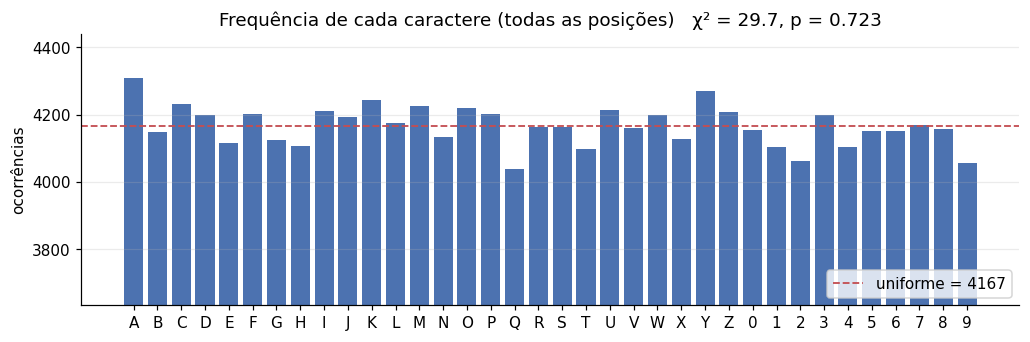

Mínimo: Q (4038)   máximo: A (4309)   desvio máximo do uniforme: 3.4%


In [6]:
chars = np.array([list(t) for t in df.texto])               # (N, 5)
contagem = pd.Series(Counter(chars.ravel())).reindex(list(VOCABULARIO), fill_value=0)
esperado = chars.size / len(VOCABULARIO)
qui2, p = stats.chisquare(contagem.values)

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(contagem.index, contagem.values, color="#4C72B0")
ax.axhline(esperado, color="#C44E52", ls="--", lw=1.2, label=f"uniforme = {esperado:.0f}")
ax.set_ylim(contagem.min() * 0.9, contagem.max() * 1.03)
ax.set_title(f"Frequência de cada caractere (todas as posições)   χ² = {qui2:.1f}, p = {p:.3f}")
ax.set_ylabel("ocorrências"); ax.legend(loc="lower right"); ax.grid(axis="x", visible=False)
salvar(fig, "01_frequencia_caracteres"); plt.show()
print(f"Mínimo: {contagem.idxmin()} ({contagem.min()})   máximo: {contagem.idxmax()} ({contagem.max()})   "
      f"desvio máximo do uniforme: {100 * np.abs(contagem / esperado - 1).max():.1f}%")

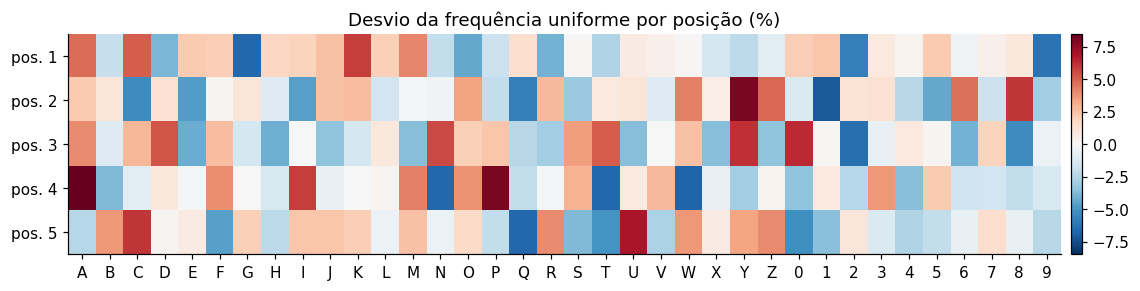

,χ²,p
pos. 1,28.274,0.783
pos. 2,35.338,0.452
pos. 3,36.050,0.419
pos. 4,38.496,0.314
pos. 5,31.181,0.653


In [7]:
por_posicao = pd.DataFrame({k: pd.Series(Counter(chars[:, k])).reindex(list(VOCABULARIO), fill_value=0)
                            for k in range(TAMANHO_TEXTO)}).T
desvio = por_posicao / (len(df) / len(VOCABULARIO)) - 1

fig, ax = plt.subplots(figsize=(12, 2.6))
lim = np.abs(desvio.values).max()
im = ax.imshow(desvio.values * 100, cmap="RdBu_r", vmin=-lim * 100, vmax=lim * 100, aspect="auto")
ax.set_xticks(range(len(VOCABULARIO)), list(VOCABULARIO)); ax.set_yticks(range(TAMANHO_TEXTO), [f"pos. {k+1}" for k in range(TAMANHO_TEXTO)])
ax.grid(False); ax.set_title("Desvio da frequência uniforme por posição (%)")
fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01)
salvar(fig, "02_heatmap_posicao_caractere"); plt.show()

teste_posicao = pd.DataFrame([dict(zip(["χ²", "p"], stats.chisquare(por_posicao.loc[k].values))) for k in range(TAMANHO_TEXTO)],
                             index=[f"pos. {k+1}" for k in range(TAMANHO_TEXTO)]).round(3)
display(teste_posicao)

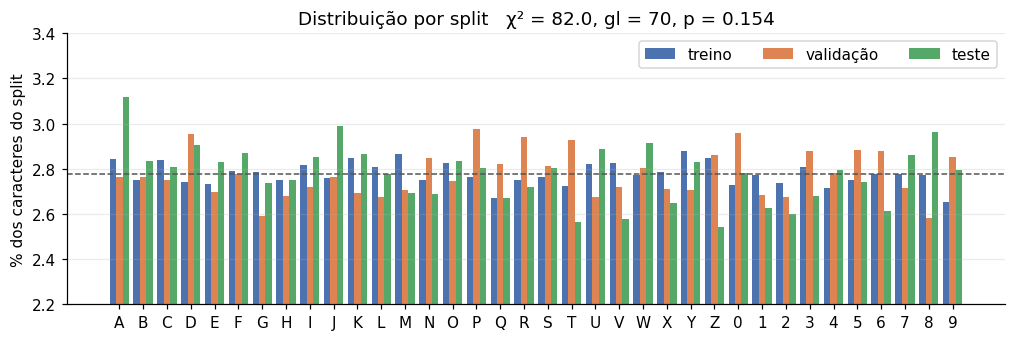

In [8]:
# Mesma distribuição de caracteres nos três splits? (teste de independência caractere × split)
tabela = pd.DataFrame({s: pd.Series(Counter(np.array([list(t) for t in df.texto[df.split == s]]).ravel()))
                       .reindex(list(VOCABULARIO), fill_value=0) for s in ORDEM_SPLITS})
qui2_s, p_s, gl, _ = stats.chi2_contingency(tabela.values)
prop = tabela / tabela.sum()

fig, ax = plt.subplots(figsize=(11, 3.2))
for i, (s, cor) in enumerate(zip(ORDEM_SPLITS, ["#4C72B0", "#DD8452", "#55A868"])):
    ax.bar(np.arange(len(VOCABULARIO)) + (i - 1) * 0.27, prop[s] * 100, width=0.27, label=s, color=cor)
ax.axhline(100 / len(VOCABULARIO), color="#555", ls="--", lw=1)
ax.set_xticks(range(len(VOCABULARIO)), list(VOCABULARIO)); ax.set_ylim(2.2, 3.4)
ax.set_ylabel("% dos caracteres do split"); ax.legend(ncol=3, loc="upper right"); ax.grid(axis="x", visible=False)
ax.set_title(f"Distribuição por split   χ² = {qui2_s:.1f}, gl = {gl}, p = {p_s:.3f}")
salvar(fig, "03_frequencia_por_split"); plt.show()

In [9]:
# CAPTCHAs com caractere repetido (ex.: AA3B7) e linha de base de chance
com_repeticao = np.array([len(set(t)) < TAMANHO_TEXTO for t in df.texto])
k = len(VOCABULARIO)
teorico = 1 - np.prod([(k - i) / k for i in range(TAMANHO_TEXTO)])
print(f"CAPTCHAs com algum caractere repetido: {com_repeticao.mean():.1%}  (teórico: {teorico:.1%})")
print(f"Distribuição de caracteres distintos por CAPTCHA: {dict(sorted(Counter(len(set(t)) for t in df.texto).items()))}")
print()
print(f"Chance por caractere: 1/36 = {1/k:.2%}")
print(f"Chance por CAPTCHA:   (1/36)^5 = {k ** -TAMANHO_TEXTO:.2e}")
print(f"Perda (soma das 5 entropias cruzadas) de um modelo que chuta: 5·ln 36 = {TAMANHO_TEXTO * np.log(k):.2f}")

CAPTCHAs com algum caractere repetido: 25.3%  (teórico: 25.2%)
Distribuição de caracteres distintos por CAPTCHA: {2: 7, 3: 545, 4: 7025, 5: 22423}

Chance por caractere: 1/36 = 2.78%
Chance por CAPTCHA:   (1/36)^5 = 1.65e-08
Perda (soma das 5 entropias cruzadas) de um modelo que chuta: 5·ln 36 = 17.92


O último valor (17,92) é exatamente a perda de validação em que ficaram paradas as rodadas do escalonamento da EfficientNet
que não convergiram (ver `resultados_bernardo/README.md`): elas não aprenderam nada além do chute.

## 4. Características visuais

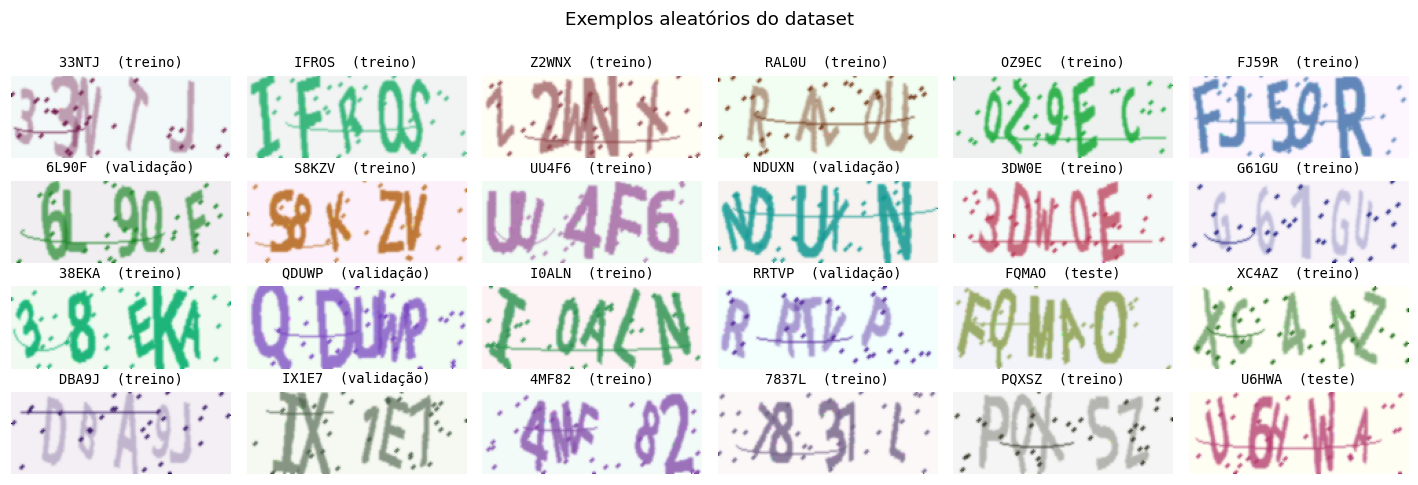

In [10]:
rng = np.random.default_rng(SEED)
amostra = img.iloc[rng.choice(len(img), 24, replace=False)]
fig, axs = plt.subplots(4, 6, figsize=(13, 4.4))
for ax, (_, linha) in zip(axs.ravel(), amostra.iterrows()):
    ax.imshow(Image.open(PASTA_DADOS / linha.arquivo)); ax.set_axis_off()
    ax.set_title(f"{linha.texto}  ({linha.split})", fontsize=9, family="monospace")
fig.suptitle("Exemplos aleatórios do dataset", y=1.0)
fig.tight_layout(); salvar(fig, "04_exemplos"); plt.show()

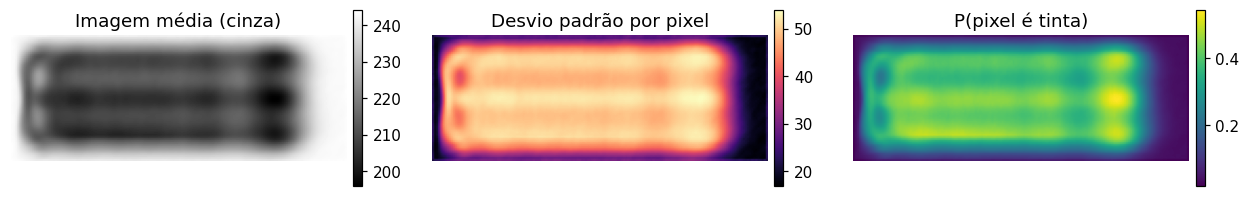

In [11]:
media = soma / n_ok
desvio_px = np.sqrt(np.maximum(soma_q / n_ok - media ** 2, 0))
prob_tinta = soma_tinta / n_ok

fig, axs = plt.subplots(1, 3, figsize=(14, 2.6))
for ax, dado, titulo, cmap in [(axs[0], media.mean(axis=2), "Imagem média (cinza)", "gray"),
                               (axs[1], desvio_px.mean(axis=2), "Desvio padrão por pixel", "magma"),
                               (axs[2], prob_tinta, "P(pixel é tinta)", "viridis")]:
    h = ax.imshow(dado, cmap=cmap); ax.set_title(titulo); ax.set_axis_off()
    fig.colorbar(h, ax=ax, fraction=0.025, pad=0.02)
salvar(fig, "05_imagem_media_desvio_tinta"); plt.show()

In [12]:
# Estatísticas RGB do próprio dataset x normalização ImageNet usada no Datamodule
media_canal = soma.sum(axis=(0, 1)) / (n_ok * ALTURA * LARGURA) / 255
desvio_canal = np.sqrt(soma_q.sum(axis=(0, 1)) / (n_ok * ALTURA * LARGURA) / 255 ** 2 - media_canal ** 2)
rgb = pd.DataFrame({"média dataset": media_canal, "média ImageNet": [0.485, 0.456, 0.406],
                    "desvio dataset": desvio_canal, "desvio ImageNet": [0.229, 0.224, 0.225]},
                   index=["R", "G", "B"]).round(3)
display(rgb)
apos_norm = (media_canal - np.array([0.485, 0.456, 0.406])) / np.array([0.229, 0.224, 0.225])
print("Média de cada canal depois do Normalize do treino:", apos_norm.round(2),
      "(o ideal seria ~0; o fundo claro fica bem acima de zero)")

,média dataset,média ImageNet,desvio dataset,desvio ImageNet
R,0.860,0.485,0.182,0.229
G,0.866,0.456,0.164,0.224
B,0.858,0.406,0.190,0.225


Média de cada canal depois do Normalize do treino: [1.64 1.83 2.01] (o ideal seria ~0; o fundo claro fica bem acima de zero)


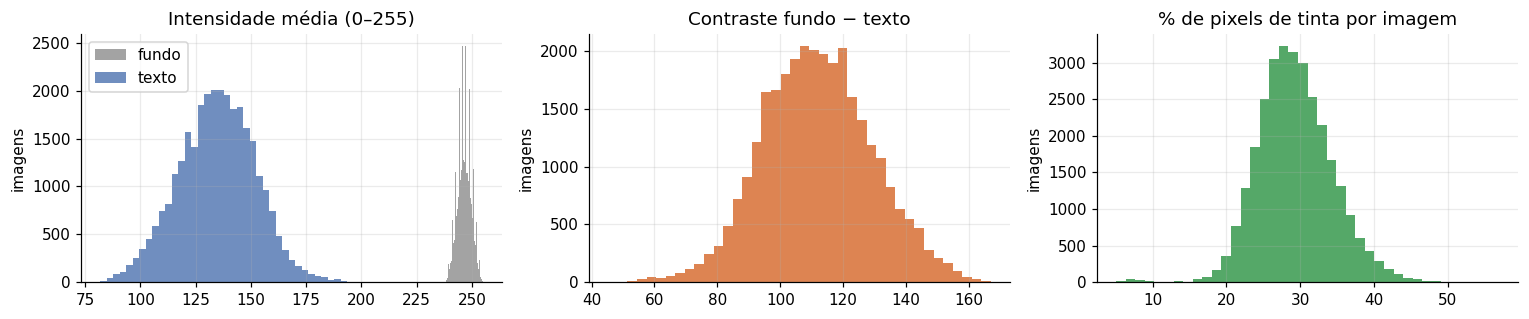

,mean,std,min,50%,max
fundo_r,246.491,5.177,238.000,247.000,255.00
fundo_g,246.513,5.228,238.000,247.000,255.00
fundo_b,246.526,5.199,238.000,247.000,255.00
texto_r,133.950,43.522,8.000,137.000,220.00
texto_g,138.320,28.707,60.000,135.000,201.00
texto_b,131.867,48.814,7.000,135.000,234.00
contraste,111.798,17.438,45.333,111.333,167.00
fracao_tinta,0.293,0.051,0.050,0.290,0.57


In [13]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3))
fundo_cinza = img[["fundo_r", "fundo_g", "fundo_b"]].mean(axis=1)
texto_cinza = img[["texto_r", "texto_g", "texto_b"]].mean(axis=1)
img["contraste"] = fundo_cinza - texto_cinza

axs[0].hist(fundo_cinza, bins=40, color="#8C8C8C", alpha=0.8, label="fundo")
axs[0].hist(texto_cinza, bins=40, color="#4C72B0", alpha=0.8, label="texto")
axs[0].set_title("Intensidade média (0–255)"); axs[0].legend()
axs[1].hist(img.contraste, bins=40, color="#DD8452"); axs[1].set_title("Contraste fundo − texto")
axs[2].hist(img.fracao_tinta * 100, bins=40, color="#55A868"); axs[2].set_title("% de pixels de tinta por imagem")
for ax in axs: ax.set_ylabel("imagens")
fig.tight_layout(); salvar(fig, "06_cores_contraste_tinta"); plt.show()

display(img[["fundo_r", "fundo_g", "fundo_b", "texto_r", "texto_g", "texto_b", "contraste", "fracao_tinta"]]
        .describe().T[["mean", "std", "min", "50%", "max"]].round(3))

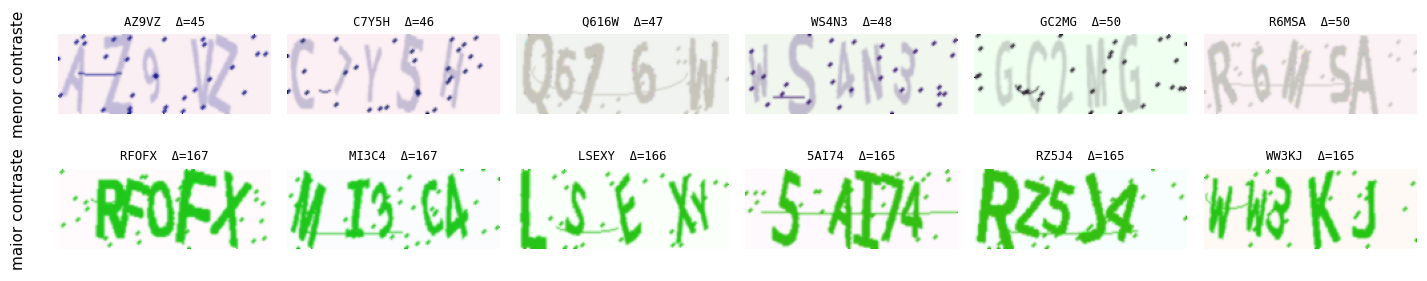

In [14]:
# Extremos de contraste: as imagens mais "apagadas" tendem a ser as mais difíceis
fig, axs = plt.subplots(2, 6, figsize=(13, 2.6))
for linha_ax, (titulo, sub) in zip(axs, [("menor contraste", img.nsmallest(6, "contraste")),
                                           ("maior contraste", img.nlargest(6, "contraste"))]):
    for ax, (_, r) in zip(linha_ax, sub.iterrows()):
        ax.imshow(Image.open(PASTA_DADOS / r.arquivo)); ax.set_axis_off()
        ax.set_title(f"{r.texto}  Δ={r.contraste:.0f}", fontsize=8, family="monospace")
    linha_ax[0].text(-0.15, 0.5, titulo, transform=linha_ax[0].transAxes, rotation=90, va="center", ha="right")
fig.tight_layout(); salvar(fig, "07_extremos_contraste"); plt.show()

## 5. Ligação com a interpretabilidade

### 5.1 Onde fica cada caractere?

O nome do arquivo não diz onde cada caractere foi desenhado. Para estimar isso, geramos novos CAPTCHAs com **o mesmo gerador**
(mesma classe, mesmos parâmetros e tamanho) instrumentado para registrar a posição de cada caractere colado na imagem.
Primeiro conferimos que a amostra simulada tem as mesmas estatísticas do dataset; depois usamos as posições como
**referência esperada** para os mapas de Grad-CAM, IG e LIME: o mapa da posição *k* deveria se concentrar perto da faixa *k*.

In [15]:
import random

import captcha.image as cimg
from captcha.image import ImageCaptcha

class SecretsComSeed(random.Random):
    # Mesmo truque do ataque_local/servidor.py: a biblioteca sorteia com `secrets`, que ignora seeds
    def randbelow(self, n): return self.randrange(n)
    def randbits(self, k): return self.getrandbits(k)

class CaptchaInstrumentado(ImageCaptcha):
    # Cópia de ImageCaptcha.create_captcha_image (captcha 0.7.x) que guarda a caixa de cada caractere
    def create_captcha_image(self, chars, color, background):
        s = cimg.secrets
        image = cimg.createImage("RGB", (self._width, self._height), background)
        draw = cimg.Draw(image)
        images, eh_char = [], []
        for c in chars:
            if s.randbits(32) / (2 ** 32) > self.word_space_probability:
                images.append(self._draw_character(" ", draw, color)); eh_char.append(False)
            images.append(self._draw_character(c, draw, color)); eh_char.append(True)
        text_width = sum(im.size[0] for im in images)
        width = max(text_width, self._width)
        image = image.resize((width, self._height))
        average = int(text_width / len(chars)); rand = int(self.word_offset_dx * average); offset = int(average * 0.1)
        caixas = []
        for im, real in zip(images, eh_char):
            w, h = im.size
            image.paste(im, (offset, int((self._height - h) / 2)), im.convert("L").point(self.lookup_table))
            if real: caixas.append((offset, offset + w))
            offset = offset + w + (-s.randbelow(rand + 1))
        escala = self._width / width
        self.ultimas_caixas = [(a * escala, b * escala) for a, b in caixas]
        self.ultima_compressao = escala
        if width > self._width:
            image = image.resize((self._width, self._height))
        return image

segredos_originais = cimg.secrets
cimg.secrets = SecretsComSeed(SEED)
gerador = CaptchaInstrumentado(width=LARGURA, height=ALTURA)
rnd = random.Random(SEED)
N_SIM = 3000
sim, sim_fracao_tinta = [], []
for i in range(N_SIM):
    texto = "".join(rnd.choices(VOCABULARIO, k=TAMANHO_TEXTO))
    a = np.asarray(gerador.generate_image(texto))
    tinta = np.abs(a.astype(int) - fundo_da_imagem(a)).max(axis=2) > LIMIAR_TINTA
    sim_fracao_tinta.append(tinta.mean())
    for k, (x0, x1) in enumerate(gerador.ultimas_caixas):
        sim.append({"id": i, "posicao": k + 1, "char": texto[k], "x0": x0, "x1": x1,
                    "centro": (x0 + x1) / 2, "compressao": gerador.ultima_compressao})
cimg.secrets = segredos_originais
sim = pd.DataFrame(sim)

print(f"Fração de tinta  dataset: {img.fracao_tinta.mean():.4f} ± {img.fracao_tinta.std():.4f}   "
      f"simulado: {np.mean(sim_fracao_tinta):.4f} ± {np.std(sim_fracao_tinta):.4f}")
ks = stats.ks_2samp(img.fracao_tinta, sim_fracao_tinta)
print(f"Teste KS entre as duas distribuições: estatística = {ks.statistic:.3f}, p = {ks.pvalue:.3f}")
comp = sim.groupby("id").compressao.first()
print(f"Imagens em que o texto não coube e foi comprimido na horizontal: {(comp < 1).mean():.1%} "
      f"(fator mediano {comp[comp < 1].median():.2f})")

Fração de tinta  dataset: 0.2931 ± 0.0511   simulado: 0.2938 ± 0.0519
Teste KS entre as duas distribuições: estatística = 0.015, p = 0.586
Imagens em que o texto não coube e foi comprimido na horizontal: 97.7% (fator mediano 0.70)


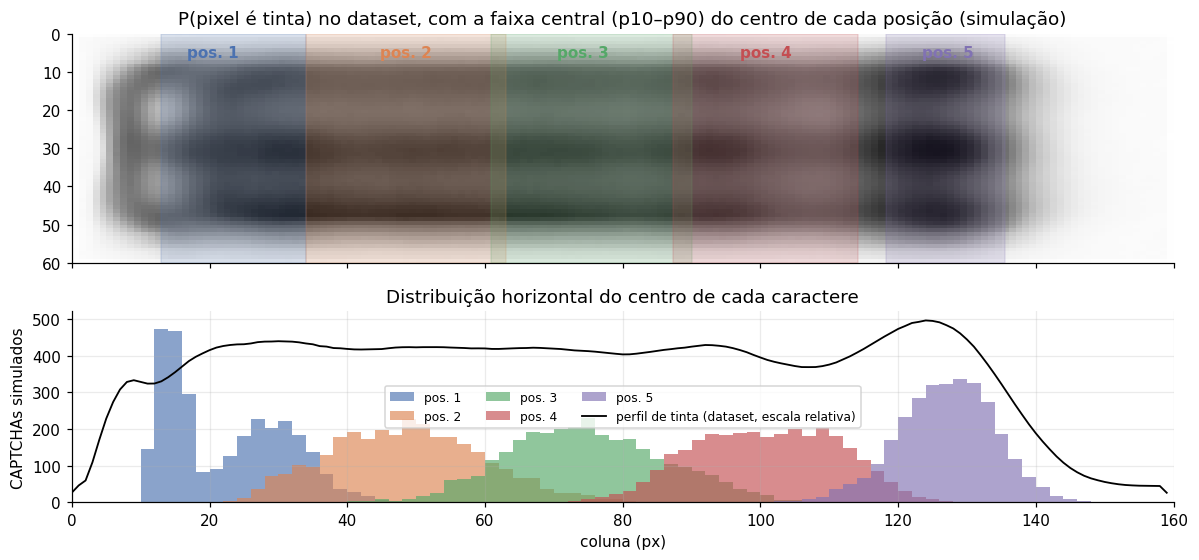

,10%,50%,90%,std
pos. 1,12.9,20.5,34.0,8.5
pos. 2,34.0,48.5,63.1,11.0
pos. 3,60.9,74.2,90.1,11.2
pos. 4,87.2,100.9,114.2,10.2
pos. 5,118.2,127.2,135.5,6.9


In [16]:
cores_pos = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
fig, axs = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})
axs[0].imshow(prob_tinta, cmap="Greys", extent=[0, LARGURA, ALTURA, 0], aspect="auto")
axs[0].set_title("P(pixel é tinta) no dataset, com a faixa central (p10–p90) do centro de cada posição (simulação)")
for k in range(1, TAMANHO_TEXTO + 1):
    c = sim[sim.posicao == k].centro
    axs[0].axvspan(c.quantile(0.1), c.quantile(0.9), color=cores_pos[k - 1], alpha=0.18)
    axs[0].text(c.median(), 6, f"pos. {k}", ha="center", color=cores_pos[k - 1], fontweight="bold")
    axs[1].hist(c, bins=np.arange(0, LARGURA + 1, 2), alpha=0.65, color=cores_pos[k - 1], label=f"pos. {k}")
axs[0].grid(False)
axs[1].plot(np.arange(LARGURA), prob_tinta.mean(axis=0) / prob_tinta.mean(axis=0).max() * axs[1].get_ylim()[1],
            color="k", lw=1.2, label="perfil de tinta (dataset, escala relativa)")
axs[1].set_xlabel("coluna (px)"); axs[1].set_ylabel("CAPTCHAs simulados"); axs[1].legend(ncol=3, fontsize=8)
axs[1].set_title("Distribuição horizontal do centro de cada caractere")
fig.tight_layout(); salvar(fig, "08_posicao_dos_caracteres"); plt.show()

faixas = sim.groupby("posicao").centro.describe(percentiles=[0.1, 0.5, 0.9])[["10%", "50%", "90%", "std"]].round(1)
faixas.index = [f"pos. {k}" for k in faixas.index]
faixas.to_csv(SAIDA / "faixas_posicao_caracteres.csv")
display(faixas)

In [17]:
# Sobreposição entre caracteres vizinhos: quanto da caixa de um invade a do próximo
viz = sim.sort_values(["id", "posicao"]).copy()
viz["prox_x0"] = viz.groupby("id").x0.shift(-1)
viz = viz.dropna(subset=["prox_x0"])
viz["sobreposicao_px"] = (viz.x1 - viz.prox_x0).clip(lower=0)
largura_media = (sim.x1 - sim.x0).mean()
por_img = viz.groupby("id").sobreposicao_px.apply(lambda s: (s > 0).any())
print(f"Largura média da caixa de um caractere: {largura_media:.1f} px")
print(f"Pares vizinhos que se sobrepõem: {(viz.sobreposicao_px > 0).mean():.1%}   "
      f"(sobreposição mediana quando há: {viz.sobreposicao_px[viz.sobreposicao_px > 0].median():.1f} px)")
print(f"CAPTCHAs com pelo menos um par sobreposto: {por_img.mean():.1%}")

Largura média da caixa de um caractere: 21.9 px
Pares vizinhos que se sobrepõem: 46.4%   (sobreposição mediana quando há: 4.1 px)
CAPTCHAs com pelo menos um par sobreposto: 92.1%


**Leitura:** os caracteres ocupam faixas horizontais previsíveis, mas largas e sobrepostas, e na maioria das imagens pelo menos
um par de vizinhos se encosta. Uma abordagem clássica de segmentar e classificar cada caractere teria dificuldade;
a CNN com 5 saídas aprende a separar sozinha. Para a análise de XAI, a tabela acima dá a **região esperada** de cada
posição: um mapa de Grad-CAM da posição 1 com massa perto de x ≈ 130 px indicaria atenção no lugar errado.

### 5.2 Glifos parecidos

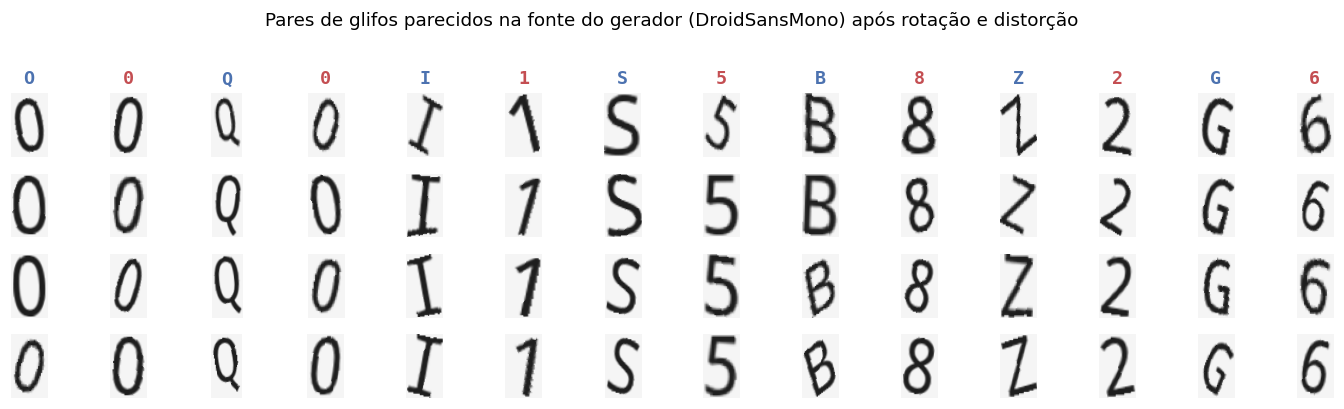

In [18]:
# Cada coluna é o mesmo caractere desenhado pelo gerador com distorções sorteadas
PARES = [("O", "0"), ("Q", "0"), ("I", "1"), ("S", "5"), ("B", "8"), ("Z", "2"), ("G", "6")]
VARIANTES = 4
cimg.secrets = SecretsComSeed(SEED)
fig, axs = plt.subplots(VARIANTES, 2 * len(PARES), figsize=(13, 3.6))
for j, c in enumerate([c for par in PARES for c in par]):
    for i in range(VARIANTES):
        tela = Image.new("RGBA", (60, 60), (0, 0, 0, 0))
        glifo = gerador._draw_character(c, cimg.Draw(tela), (30, 30, 30, 255))
        fundo = Image.new("RGB", glifo.size, (245, 245, 245)); fundo.paste(glifo, (0, 0), glifo)
        axs[i, j].imshow(fundo); axs[i, j].set_axis_off()
    axs[0, j].set_title(c, family="monospace", fontweight="bold", color="#C44E52" if j % 2 else "#4C72B0")
cimg.secrets = segredos_originais
fig.suptitle("Pares de glifos parecidos na fonte do gerador (DroidSansMono) após rotação e distorção", y=1.02)
fig.tight_layout(); salvar(fig, "09_glifos_parecidos"); plt.show()

## 6. Que trocas os modelos realmente fazem?

Usa os CSVs do ataque local (`ataque_local/resultados/<modelo>/tentativas.csv`, 500 CAPTCHAs novos do mesmo gerador,
servidor com `--seed 42`, mesmas imagens para os dois modelos). Cada caractere errado vira um par (correto → previsto).

,CAPTCHAs,erros de caractere,pares distintos
modelo,,,
AlexNetCaptcha,500,100,58
EfficientNetCaptcha,500,18,11


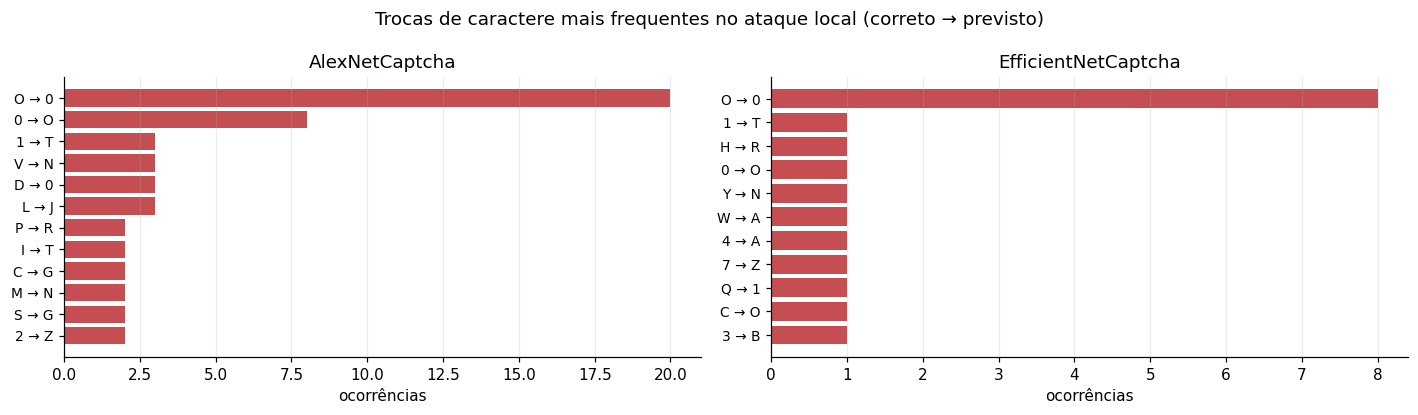

AlexNetCaptcha: 34% dos erros de caractere caem nos pares parecidos da seção 5.2
EfficientNetCaptcha: 50% dos erros de caractere caem nos pares parecidos da seção 5.2


In [19]:
trocas, resumo_ataque = {}, []
for modelo in ["AlexNetCaptcha", "EfficientNetCaptcha"]:
    caminho = RAIZ / "ataque_local" / "resultados" / modelo / "tentativas.csv"
    if not caminho.exists():
        print(f"(sem {caminho.relative_to(RAIZ)}: rode o ataque local para esta seção)"); continue
    t = pd.read_csv(caminho, dtype=str)
    pares = Counter((c, p) for prev, corr in zip(t.previsto, t.correto) for c, p in zip(corr, prev) if c != p)
    trocas[modelo] = pares
    resumo_ataque.append({"modelo": modelo, "CAPTCHAs": len(t), "erros de caractere": sum(pares.values()),
                          "pares distintos": len(pares)})
display(pd.DataFrame(resumo_ataque).set_index("modelo"))

if trocas:
    fig, axs = plt.subplots(1, len(trocas), figsize=(13, 3.8))
    for ax, (modelo, pares) in zip(np.atleast_1d(axs), trocas.items()):
        top = pares.most_common(12)[::-1]
        ax.barh([f"{c} → {p}" for (c, p), _ in top], [n for _, n in top], color="#C44E52")
        ax.set_title(modelo); ax.set_xlabel("ocorrências"); ax.grid(axis="y", visible=False)
        ax.tick_params(axis="y", labelsize=9)
    fig.suptitle("Trocas de caractere mais frequentes no ataque local (correto → previsto)")
    fig.tight_layout(); salvar(fig, "10_trocas_ataque_local"); plt.show()

    tab = pd.DataFrame([{"modelo": m, "correto": c, "previsto": p, "ocorrências": n}
                        for m, pares in trocas.items() for (c, p), n in pares.items()])
    tab.sort_values(["modelo", "ocorrências"], ascending=[True, False]).to_csv(SAIDA / "trocas_ataque_local.csv", index=False)
    parecidos = {frozenset(p) for p in PARES}
    for m, pares in trocas.items():
        n_par = sum(n for (c, p), n in pares.items() if frozenset((c, p)) in parecidos)
        print(f"{m}: {n_par / sum(pares.values()):.0%} dos erros de caractere caem nos pares parecidos da seção 5.2")

## 7. Resumo

In [20]:
resumo = pd.Series({
    "imagens": f"{len(df):,}",
    "arquivos com problema": len(problemas),
    "textos únicos": f"{df.texto.nunique():,}",
    "textos repetidos que cruzam splits": int(cruzados["cruza splits?"].sum()),
    "imagens idênticas (hash)": len(hash_repetido),
    "split treino/val/teste": " / ".join(f"{(df.split == s).sum():,}" for s in ORDEM_SPLITS),
    "χ² uniformidade dos caracteres (p)": f"{p:.3f}",
    "χ² caractere × split (p)": f"{p_s:.3f}",
    "CAPTCHAs com caractere repetido": f"{com_repeticao.mean():.1%}",
    "média RGB do dataset": ", ".join(f"{v:.3f}" for v in media_canal),
    "fração de tinta média": f"{img.fracao_tinta.mean():.1%}",
    "CAPTCHAs com caracteres sobrepostos (sim.)": f"{por_img.mean():.1%}",
}, name="valor")
resumo.to_frame().to_csv(SAIDA / "resumo_eda.csv")
img.drop(columns=["modo", "largura", "altura"]).to_csv(SAIDA / "estatisticas_por_imagem.csv", index=False)
display(resumo.to_frame())
print("Figuras e tabelas salvas em", SAIDA.relative_to(RAIZ))

,valor
imagens,"30,000"
arquivos com problema,0
textos únicos,"29,992"
textos repetidos que cruzam splits,3
imagens idênticas (hash),0
split treino/val/teste,"21,000 / 4,500 / 4,500"
χ² uniformidade dos caracteres (p),0.723
χ² caractere × split (p),0.154
CAPTCHAs com caractere repetido,25.3%
média RGB do dataset,"0.860, 0.866, 0.858"


Figuras e tabelas salvas em resultados_bernardo/eda


## Conclusões

1. **Dados íntegros.** As 30.000 imagens são RGB 160×60 e seguem o padrão de nome. Nenhuma está corrompida e nenhuma é cópia de outra. Há 8 textos repetidos, o esperado ao acaso (≈7,4). Três deles cruzam splits, mas como imagens diferentes, então o vazamento é desprezível.
2. **Rótulos equilibrados.** A frequência dos caracteres é compatível com a uniforme no geral, em cada posição e entre treino, validação e teste (todos os p > 0,05). O split aleatório não criou viés. Cerca de 25% dos CAPTCHAs repetem algum caractere, como manda a teoria.
3. **Imagens claras, com texto de cor variável.** O fundo fica entre 238 e 255, e o texto e o ruído ocupam cerca de 29% dos pixels. A média RGB do dataset (≈0,86) é muito diferente da média do ImageNet usada no `Normalize`, então as entradas chegam à rede com média de ~1,6 a 2,0 em vez de 0. A rede funciona mesmo assim (98,99% no teste). Normalizar com as estatísticas do próprio dataset seria um ajuste simples a testar, por exemplo nas rodadas de escalonamento que não convergiram.
4. **Caracteres em faixas previsíveis, mas sobrepostas.** Em 98% das imagens o texto foi comprimido na horizontal para caber, e 92% dos CAPTCHAs têm pelo menos um par de vizinhos se tocando. A tabela `faixas_posicao_caracteres.csv` dá a região esperada de cada posição para validar os mapas de XAI. A posição 1 tem duas faixas porque, em metade dos casos, o gerador insere um espaço antes do primeiro caractere.
5. **Os erros dos modelos são sobretudo de glifos parecidos.** A troca O ↔ 0 domina nos dois modelos: 28 dos 100 erros de caractere da AlexNet e 9 dos 18 da EfficientNet. Isso é coerente com a fonte do gerador, em que O e 0 só se distinguem pela largura.
